# Random Forest · Itens 3, 4 e 5

Execute as células em ordem com o kernel R e o pacote `ranger` instalado. O gráfico e as tabelas da execução de referência estão incluídos para leitura.

## Item 3. Como a floresta escolhe um corte

Imagine uma árvore que prevê o preço mediano dos imóveis de um distrito. No bagging, cada árvore recebe uma amostra bootstrap de distritos. Se a renda for um preditor forte, várias árvores poderão começar pelo mesmo corte de renda. Quando todas cometem erros parecidos nos mesmos distritos, tirar a média corrige pouco esses erros.

No algoritmo de Breiman com sorteio de atributos, a árvore recebe uma amostra bootstrap e, a cada nó, sorteia sem reposição `mtry` variáveis candidatas. Entre os cortes possíveis nessas variáveis, escolhe aquele que mais reduz a soma dos quadrados dos resíduos. Cada folha prevê a média dos preços de treino que chegaram até ela. A floresta calcula a média das previsões das árvores. [Breiman, *Random Forests*, 2001](https://doi.org/10.1023/A:1010933404324)

Considere quatro preditores: renda, latitude, idade e população. Com duas candidatas por nó, um sorteio na raiz pode oferecer renda e idade. A árvore escolhe renda. No ramo de menor renda, um novo sorteio pode oferecer latitude e população, permitindo separar distritos pela localização. No método de Ho, se a árvore recebe renda e idade, apenas essas duas variáveis ficam disponíveis ao longo de todos os seus ramos. Assim, **Breiman não se limitou a aplicar o subespaço de Ho**. O momento do sorteio muda inclusive quais interações uma árvore consegue representar. [Ho, *The Random Subspace Method for Constructing Decision Forests*, 1998](https://doi.org/10.1109/34.709601)

Para um distrito fixo, suponha que cada previsão tenha variância σ² e que os pares de previsões tenham correlação ρ nas repetições do treinamento. Somando as B variâncias e as B(B−1) covariâncias, a variância da média fica **σ²[ρ + (1−ρ)/B]**. Por exemplo, com σ² = 100 e B = 100, reduzir ρ de 0,8 para 0,3 reduz essa variância de 80,2 para 30,7. A hipótese de variâncias iguais serve para isolar o efeito da correlação.

Há um custo possível: quando uma variável decisiva fica fora do sorteio, a árvore pode escolher um corte inferior. Se isso acontece repetidamente, a previsão média pode se afastar do valor esperado do imóvel e o viés aumentar. Como o erro quadrático esperado inclui viés ao quadrado, variância e ruído, reduzir `mtry` só melhora o erro total se o ganho compensar esse custo.

## Item 4. Como calcular o erro out-of-bag

Em um bootstrap de n sorteios com reposição, a chance de um distrito específico ficar de fora é (1−1/n)ⁿ, aproximadamente 36,8% para n grande. Essas árvores podem prever o distrito sem terem usado seu preço no ajuste. O conjunto de árvores elegíveis muda de um distrito para outro.

**Exemplo para desenhar no relatório.** Imagine três árvores e dois distritos com preços em milhares de dólares. Um traço indica que a árvore recebeu aquele distrito no bootstrap.

| Distrito | Preço observado | Árvore 1 | Árvore 2 | Árvore 3 | Média OOB |
|---|---:|---:|---:|---:|---:|
| A | 100 | 90 | — | 110 | 100 |
| B | 160 | — | 140 | — | 140 |

Primeiro tiramos a média das previsões elegíveis **dentro de cada linha**. Só então calculamos os erros por distrito. O RMSE OOB do exemplo é √[(0² + 20²)/2] = 14,14 mil dólares. Isso dá o mesmo peso aos dois distritos, embora A tenha recebido mais previsões. Se uma linha ainda não recebeu previsão OOB, ela fica fora do denominador. A cobertura é a fração de linhas que já receberam pelo menos uma previsão.

**Experimento.** Dividimos aleatoriamente o California housing em 10.216 distritos de treino e 10.217 de teste, com semente 42. Usamos os nove preditores originais e tratamos a proximidade do oceano como categórica. Ajustamos uma floresta de regressão com 300 árvores, bootstrap de tamanho igual ao treino e três candidatas por nó. Para cada B de 1 a 300, usamos as primeiras B árvores da mesma floresta. Cada distrito de teste recebe B previsões. Cada distrito de treino recebe somente as previsões das árvores que o deixaram de fora. O código verifica o último RMSE OOB contra a raiz do MSE informado pelo próprio pacote. [Documentação do ranger](https://imbs-hl.github.io/ranger/reference/ranger.html)

In [1]:
if (!file.exists("data/california.csv") && file.exists("../../data/california.csv")) setwd("../..")
library(ranger)
saida <- "src/markdown/figuras_random_forest"
dir.create(saida, recursive = TRUE, showWarnings = FALSE)
dados <- read.csv("data/california.csv")
dados$ocean_proximity <- factor(dados$ocean_proximity)
stopifnot(!anyNA(dados))
set.seed(42)
indices <- sample.int(nrow(dados), floor(nrow(dados) / 2))
treino <- dados[indices, ]
teste <- dados[-indices, ]

In [2]:
# Uma única floresta permite comparar as primeiras B árvores de cada vez.
floresta <- ranger(median_house_value ~ ., data = treino, num.trees = 300,
                   mtry = 3, min.node.size = 5, keep.inbag = TRUE,
                   replace = TRUE, sample.fraction = 1,
                   respect.unordered.factors = "partition",
                   importance = "permutation", seed = 42, num.threads = 1)

In [3]:
por_arvore <- function(dados) {
  predict(floresta, data = dados, predict.all = TRUE, num.threads = 1)$predictions
}
pred_treino <- por_arvore(treino)
pred_teste <- por_arvore(teste)
soma_oob <- votos <- numeric(nrow(treino))
soma_teste <- numeric(nrow(teste))
curva <- data.frame(arvores = seq_len(floresta$num.trees), cobertura = NA_real_,
                    rmse_oob = NA_real_, rmse_teste = NA_real_)
for (b in curva$arvores) {
  fora <- floresta$inbag.counts[[b]] == 0
  soma_oob[fora] <- soma_oob[fora] + pred_treino[fora, b]
  votos[fora] <- votos[fora] + 1
  coberto <- votos > 0
  soma_teste <- soma_teste + pred_teste[, b]
  curva$cobertura[b] <- mean(coberto)
  curva$rmse_oob[b] <- sqrt(mean((treino$median_house_value[coberto] -
                                  soma_oob[coberto] / votos[coberto])^2))
  curva$rmse_teste[b] <- sqrt(mean((teste$median_house_value - soma_teste / b)^2))
}

In [4]:
stopifnot(isTRUE(all.equal(tail(curva$rmse_oob, 1), sqrt(floresta$prediction.error))),
          isTRUE(all.equal(soma_teste / floresta$num.trees,
                           predict(floresta, data = teste)$predictions)))

curva[c(1,5,10,50,100,300), ]

,arvores,cobertura,rmse_oob,rmse_teste
,<int>,<dbl>,<dbl>,<dbl>
1,1,0.3693226,78023.30,76882.47
5,5,0.8996672,67990.94,57297.24
10,10,0.9895262,60133.64,53701.87
50,50,1.0000000,51949.63,51063.69
100,100,1.0000000,51082.19,50800.93
300,300,1.0000000,50496.93,50648.79


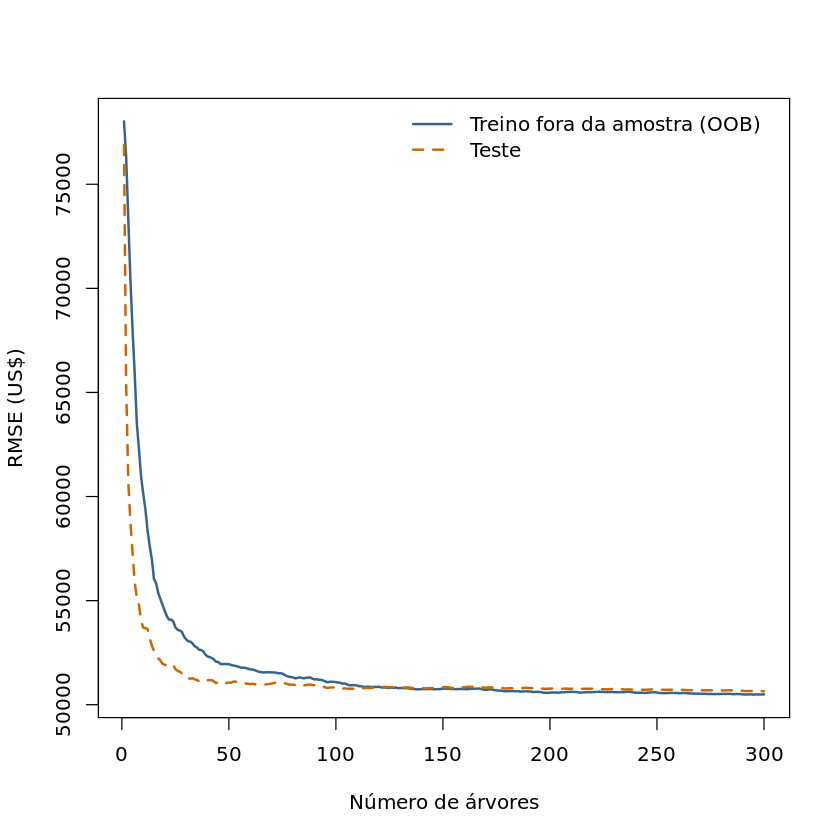

In [5]:
matplot(curva$arvores, curva[c("rmse_oob","rmse_teste")], type = "l", lty = 1:2,
        col = c("steelblue4","darkorange3"), lwd = 2,
        xlab = "Número de árvores", ylab = "RMSE (US$)")
legend("topright", c("Treino fora da amostra (OOB)", "Teste"),
       col = c("steelblue4","darkorange3"), lty = 1:2, lwd = 2, bty = "n")

![RMSE OOB e de teste ao acrescentar árvores](../markdown/figuras_random_forest/erro_oob.png)

| Árvores | Cobertura OOB | RMSE OOB (US$) | RMSE de teste (US$) |
|---:|---:|---:|---:|
| 1 | 36,93% | 78.023 | 76.882 |
| 5 | 89,97% | 67.991 | 57.297 |
| 10 | 98,95% | 60.134 | 53.702 |
| 50 | 100% | 51.950 | 51.064 |
| 100 | 100% | 51.082 | 50.801 |
| 300 | 100% | 50.497 | 50.649 |

Com cinco árvores, a diferença ultrapassou US$ 10 mil. Mesmo tendo previsão OOB, muitos distritos ainda dependiam de apenas uma ou duas árvores. Com 50 árvores, todos os distritos já tinham previsão OOB e a diferença caiu para US$ 886. Com 300, o erro OOB ficou US$ 152 abaixo do erro de teste, uma diferença de 0,30%. A aproximação observada tem oscilações: as curvas usam distritos distintos e cada média OOB usa menos árvores que a previsão de teste correspondente.

## Item 5. Como construir a tabela de importância

A definição da coluna determina o significado do ranking. Na **importância por redução de impureza**, cada nó de regressão contribui com a redução da soma dos quadrados obtida pelo corte: SQ do nó pai menos a soma das SQ dos filhos. Credita-se o ganho à variável que definiu o corte, somam-se seus ganhos na árvore e agrega-se entre árvores. Se a tabela for normalizada para somar 100%, a porcentagem representa a participação nos ganhos de corte. Uma variável com muitos pontos de corte possíveis pode ter vantagem nessa medida. [Strobl et al., 2007](https://doi.org/10.1186/1471-2105-8-25)

Para a tabela deste estudo, usamos **importância por permutação OOB**. Em cada árvore, calculamos o MSE nos seus distritos OOB. Em seguida, embaralhamos os valores de uma variável entre esses distritos, preservamos os preços observados e as demais colunas e voltamos a prever com a árvore já ajustada. Subtraímos o MSE original do MSE após a permutação. Repetimos para cada variável e calculamos a média das diferenças entre árvores. Ordenamos a tabela pelo aumento médio do MSE, em dólares ao quadrado, sem padronizar. [Breiman e Cutler, importância por permutação](https://www.stat.berkeley.edu/~breiman/forests/cc_home.htm#varimp)

**Exemplo numérico.** Dois distritos OOB valem 100 e 200 mil dólares. Uma árvore prevê 110 e 190, com MSE igual a 100 em (mil dólares)². Ao trocar as rendas entre os distritos, suponha que passe a prever 190 e 110. O MSE sobe para 8.100 e a renda recebe contribuição de 8.000 nessa árvore. Se trocar as idades preservar as previsões, a contribuição da idade será zero. Na floresta, uma variável pode até ter valor negativo quando a permutação melhora a previsão por acaso. Variáveis correlacionadas também podem substituir umas às outras. O ranking descreve a dependência preditiva da floresta ajustada e não mede efeito causal sobre o preço.

In [6]:
importancia <- sort(floresta$variable.importance, decreasing = TRUE)

data.frame(variavel = names(importancia), aumento_mse = unname(importancia))

variavel,aumento_mse
<chr>,<dbl>
median_income,9252534119
longitude,6370703836
latitude,5661021533
ocean_proximity,3813654178
population,2445789553
total_rooms,2279017765
total_bedrooms,1538429236
households,1370968452
housing_median_age,1050576988


| Posição | Variável | Aumento médio do MSE (bilhões de US$²) |
|---:|---|---:|
| 1 | Renda mediana | 9,25 |
| 2 | Longitude | 6,37 |
| 3 | Latitude | 5,66 |
| 4 | Proximidade do oceano | 3,81 |
| 5 | População | 2,45 |
| 6 | Total de cômodos | 2,28 |
| 7 | Total de quartos | 1,54 |
| 8 | Domicílios | 1,37 |
| 9 | Idade mediana dos imóveis | 1,05 |

Embaralhar a renda mediana provocou a maior perda de precisão OOB. Longitude e latitude vieram em seguida, indicando que a floresta depende da localização para prever os preços. A unidade é quadrática porque o cálculo compara MSEs. O valor 9,25 da primeira linha não representa uma variação de preço em dólares nem uma porcentagem.